# Crack Segmentation Project Notebook

**Cross-Surface Generalization in U-Net Based Crack Segmentation**
A Study of Encoder Backbones, Loss Functions, and Classical Preprocessing

CSE463 Computer Vision. Section 03. Summer 2026. BRAC University.
Course Instructor: Dr. Md. Ashraful Alam (ASA).
Zawad Ahsan 23201136. Yeamin Alam 23241007.

---

### What this notebook does

It builds the data pipeline, trains twelve models, and produces four result tables and three figures.
Run `00_data_audit.ipynb` first. This notebook reads its output from Drive.

### Confirmed dataset facts

| Fact | Value |
|---|---|
| Total images | 11,298 |
| After deduplication | 10,967 |
| Exact duplicates removed | 331 |
| Official split | 9,320 train, 1,647 test (deduplicated) |
| Resolution | 448 by 448, uniform |
| Mean crack pixel ratio | 3.67 percent |
| Background to crack | 26.23 to 1 |
| Mask type | Not clean binary. Threshold at 127. |
| Leaked test images | 48 of 1,695 (2.83 percent) |
| Wall family | 4,864 images |
| Pavement family | 4,248 images |

### How to survive disconnects

The run registry on Drive records every finished run.
Rerun this notebook after any disconnect. Finished runs print SKIP and take seconds.

## 1. Setup and configuration

All tunable values live here. Change values in this cell only.

`QUICK_TEST = True` runs 12 steps per epoch for 2 epochs on 240 images. Finishes in about 5 minutes.
`QUICK_TEST = False` runs the real experiment. All 12 runs take about 2 hours on a T4.

**Final run configuration used:**
- Batch 48. Crop 128. Epochs 10. Steps per epoch 150. 1,500 gradient updates per run.
- Mixed precision float16. Evaluation at full 448 resolution.

In [1]:
!pip install -q kaggle

import os
import re
import gc
import json
import time
import random
import shutil
import hashlib
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (ModelCheckpoint, EarlyStopping,
                                        ReduceLROnPlateau, CSVLogger)

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- switches
QUICK_TEST = False         # True runs a tiny sanity pass. Set False for real runs.
MIXED_PRECISION = True     # T4 tensor cores. Roughly two times faster.

# ---------------------------------------------------------------- constants
SEED = 42
FULL_SIZE = 448
CROP_SIZE = 128            # a hairline crack is still full width at 128
MASK_THRESHOLD = 127

BATCH = 32                 # section 10 probes and may lower this
EVAL_BATCH = 16
EPOCHS = 10
STEPS_PER_EPOCH = 150      # fixed budget. Every run gets identical compute.
VAL_CAP = 320              # validation subset size, for speed
FREEZE_EPOCHS = 3
LR_HEAD = 1e-3
LR_FINE = 1e-4
PATIENCE_STOP = 4
PATIENCE_LR = 2
VAL_FRACTION = 0.15

TVERSKY_ALPHA = 0.3
TVERSKY_BETA = 0.7

if QUICK_TEST:
    EPOCHS = 2
    STEPS_PER_EPOCH = 12
    FREEZE_EPOCHS = 1
    VAL_CAP = 64
    QUICK_TRAIN_N = 240
    QUICK_VAL_N = 80
    QUICK_TEST_N = 80

if MIXED_PRECISION:
    keras.mixed_precision.set_global_policy("mixed_float16")

T_START = time.time()


def elapsed():
    return round((time.time() - T_START) / 60, 1)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

DATA_ROOT = Path("/content/data")
DRIVE_DIR = Path("/content/drive/MyDrive/cse463")
RUNS_DIR = DRIVE_DIR / "runs"
FIG_DIR = DRIVE_DIR / "figures"


def rule(title):
    print("=" * 74)
    print(title)
    print("=" * 74)


def row(label, value, width=46):
    print(str(label).ljust(width) + str(value))


rule("CONFIGURATION")
row("Quick test mode", QUICK_TEST)
row("Seed", SEED)
row("Train crop size", CROP_SIZE)
row("Evaluation size", FULL_SIZE)
row("Batch size", BATCH)
row("Epochs and steps per epoch", str(EPOCHS) + " x " + str(STEPS_PER_EPOCH))
row("Gradient updates per run", EPOCHS * STEPS_PER_EPOCH)
row("Mixed precision", keras.mixed_precision.global_policy().name)
row("Mask threshold", MASK_THRESHOLD)
print()
gpus = tf.config.list_physical_devices("GPU")
row("TensorFlow version", tf.__version__)
row("GPU devices", gpus if gpus else "NONE. Enable GPU in Runtime settings.")
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

CONFIGURATION
Quick test mode                               False
Seed                                          42
Train crop size                               128
Evaluation size                               448
Batch size                                    32
Epochs and steps per epoch                    10 x 150
Gradient updates per run                      1500
Mixed precision                               mixed_float16
Mask threshold                                127

TensorFlow version                            2.20.0
GPU devices                                   [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Tesla T4, 15360 MiB


## 2. Mount Drive and download data

Mounts Drive. Downloads and unzips the dataset when missing.

Data stays on local disk at `/content/data`. All outputs go to Drive at `MyDrive/cse463`.
Local disk is wiped on disconnect. Drive is not.

In [2]:
from google.colab import drive, userdata

drive.mount("/content/drive")
for d in [DRIVE_DIR, RUNS_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

if DATA_ROOT.exists() and any(DATA_ROOT.iterdir()):
    print("Data already present. Download skipped.")
else:
    !kaggle datasets download -d lakshaymiddha/crack-segmentation-dataset -p /content --force
    !mkdir -p /content/data
    !unzip -q -o /content/crack-segmentation-dataset.zip -d /content/data

found = {}
for dirpath, dirnames, filenames in os.walk(DATA_ROOT):
    d = Path(dirpath)
    if d.name.lower() in {"images", "masks"}:
        found[(d.parent.name.lower(), d.name.lower())] = d

TRAIN_IMG = found[("train", "images")]
TRAIN_MSK = found[("train", "masks")]
TEST_IMG = found[("test", "images")]
TEST_MSK = found[("test", "masks")]

rule("PATHS")
row("Train images", TRAIN_IMG)
row("Test images", TEST_IMG)
row("Drive output", DRIVE_DIR)

Mounted at /content/drive
Dataset URL: https://www.kaggle.com/datasets/lakshaymiddha/crack-segmentation-dataset
License(s): unknown
100% 1.98G/1.98G [00:20<00:00, 104MB/s]

PATHS
Train images                                  /content/data/crack_segmentation_dataset/train/images
Test images                                   /content/data/crack_segmentation_dataset/test/images
Drive output                                  /content/drive/MyDrive/cse463


## 3. Load audit output

Reads three files written by `00_data_audit.ipynb`:

- `dedup_drop_list.json` - 331 filename stems to remove before splitting
- `surface_families.json` - maps each filename prefix to a surface family
- If either file is missing, this cell rebuilds it by rehashing all images. That takes about two minutes.

In [3]:
def prefix_of(name):
    return Path(name).stem.split("_")[0]


def md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}


def list_files(folder):
    return sorted([p for p in Path(folder).iterdir()
                   if p.is_file() and p.suffix.lower() in IMG_EXT])


train_imgs = list_files(TRAIN_IMG)
test_imgs = list_files(TEST_IMG)
all_imgs = train_imgs + test_imgs

drop_path = DRIVE_DIR / "dedup_drop_list.json"
fam_path = DRIVE_DIR / "surface_families.json"

if drop_path.exists():
    DROP_SET = set(json.loads(drop_path.read_text()))
    print("Loaded drop list from Drive.")
else:
    print("Drop list missing. Rebuilding by hashing. This takes about two minutes.")
    hmap = defaultdict(list)
    for i, p in enumerate(all_imgs, 1):
        hmap[md5_of(p)].append(p.name)
        if i % 3000 == 0:
            print("  hashed", i, "of", len(all_imgs))
    DROP_SET = set()
    for h, names in hmap.items():
        for n in sorted(names)[1:]:
            DROP_SET.add(n)
    drop_path.write_text(json.dumps(sorted(DROP_SET), indent=1))

if fam_path.exists():
    FAMILY = json.loads(fam_path.read_text())
else:
    FAMILY = {
        "CRACK500": "pavement", "GAPS384": "pavement", "cracktree200": "pavement",
        "CFD": "pavement", "forest": "pavement", "Sylvie": "pavement",
        "Rissbilder": "wall", "Volker": "wall", "Eugen": "wall",
        "DeepCrack": "mixed", "noncrack": "crack free",
    }
    fam_path.write_text(json.dumps(FAMILY, indent=2))

rule("AUDIT ARTIFACTS")
row("Files in drop list", len(DROP_SET))
row("Prefixes mapped", len(FAMILY))
row("Families", sorted(set(FAMILY.values())))

Loaded drop list from Drive.
AUDIT ARTIFACTS
Files in drop list                            331
Prefixes mapped                               11
Families                                      ['crack free', 'mixed', 'pavement', 'wall']


## 4. Build the file index

Builds a single DataFrame covering all 11,298 images.

Each row records the image path, mask path, split, prefix, surface family, crack free flag, and duplicate flag.
All splits are filters on this table. Nothing else reads raw file lists.

**Result:** 10,967 rows after removing 331 duplicates. Zero missing masks.

In [4]:
rows = []
for p in all_imgs:
    split = "train" if p.parent == TRAIN_IMG else "test"
    mdir = TRAIN_MSK if split == "train" else TEST_MSK
    pre = prefix_of(p.name)
    rows.append({
        "name": p.name,
        "image": str(p),
        "mask": str(Path(mdir) / p.name),
        "split": split,
        "prefix": pre,
        "family": FAMILY.get(pre, "unassigned"),
        "noncrack": p.stem.lower().startswith("noncrack"),
        "duplicate": p.name in DROP_SET,
    })

df = pd.DataFrame(rows)
df_clean = df[~df["duplicate"]].reset_index(drop=True)

rule("FILE INDEX")
row("Total rows", len(df))
row("Rows after dedup", len(df_clean))
row("Dropped as duplicate", int(df["duplicate"].sum()))
print()
print("Family counts after dedup:")
print(df_clean["family"].value_counts().to_string())
print()
print("Split counts after dedup:")
print(df_clean["split"].value_counts().to_string())

missing = df_clean[~df_clean["mask"].apply(lambda x: Path(x).exists())]
row("Rows with a missing mask file", len(missing))
if len(missing):
    print("FAIL. Missing masks found. Inspect before continuing.")

FILE INDEX
Total rows                                    11298
Rows after dedup                              10967
Dropped as duplicate                          331

Family counts after dedup:
family
wall          4864
pavement      4248
crack free    1334
mixed          521

Split counts after dedup:
split
train    9320
test     1647
Rows with a missing mask file                 0


## 5. Define the splits

Builds the four splits used in the study.

| Split | Train | Val | Test | Purpose |
|---|---|---|---|---|
| A | 7,922 | 1,398 | 1,647 | Official split, deduplicated |
| B_wall | 4,054 | 715 | 4,864 | Hold out wall family |
| B_pavement | 4,578 | 807 | 4,248 | Hold out pavement family |
| B_control | 4,054 | 715 | 4,864 | Random split, size matched to B_wall |

The control is the critical design decision. B_wall and B_control have identical training sizes.
Any Dice gap between them comes from domain shift alone, not data volume.

Val split is stratified by source prefix so each source keeps its share in both train and val.

In [5]:
def stratified_val_split(frame, frac, seed):
    val_parts = []
    for pre, grp in frame.groupby("prefix"):
        n_val = max(1, int(round(len(grp) * frac)))
        val_parts.append(grp.sample(n=n_val, random_state=seed))
    val = pd.concat(val_parts)
    train = frame.drop(val.index)
    return train.reset_index(drop=True), val.reset_index(drop=True)


official_train = df_clean[df_clean["split"] == "train"]
official_test_all = df[df["split"] == "test"]
official_test_clean = df_clean[df_clean["split"] == "test"]

A_train, A_val = stratified_val_split(official_train, VAL_FRACTION, SEED)
A_test = official_test_clean.reset_index(drop=True)
A_test_official = official_test_all.reset_index(drop=True)

crack_only = df_clean[df_clean["family"].isin(["wall", "pavement", "mixed"])]

SPLITS = {}
SPLITS["A"] = {"train": A_train, "val": A_val, "test": A_test,
               "note": "official split, deduplicated"}

for held in ["wall", "pavement"]:
    test_part = crack_only[crack_only["family"] == held]
    rest = crack_only[crack_only["family"] != held]
    tr, va = stratified_val_split(rest, VAL_FRACTION, SEED)
    SPLITS["B_" + held] = {"train": tr, "val": va,
                           "test": test_part.reset_index(drop=True),
                           "note": "hold out " + held}

n_tr_target = len(SPLITS["B_wall"]["train"])
n_va_target = len(SPLITS["B_wall"]["val"])
ctrl = crack_only.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
SPLITS["B_control"] = {
    "train": ctrl.iloc[:n_tr_target].reset_index(drop=True),
    "val": ctrl.iloc[n_tr_target:n_tr_target + n_va_target].reset_index(drop=True),
    "test": ctrl.iloc[n_tr_target + n_va_target:].reset_index(drop=True),
    "note": "random split, training size matched to B_wall",
}

rule("SPLITS")
print("split".ljust(16) + "train".rjust(9) + "val".rjust(8) + "test".rjust(9) + "   note")
print("-" * 74)
for k, v in SPLITS.items():
    print(k.ljust(16) + str(len(v["train"])).rjust(9) + str(len(v["val"])).rjust(8)
          + str(len(v["test"])).rjust(9) + "   " + v["note"])
print("-" * 74)
row("Official test with duplicates", len(A_test_official))
row("Official test deduplicated", len(A_test))
row("Leaked test images removed", len(A_test_official) - len(A_test))

SPLITS
split               train     val     test   note
--------------------------------------------------------------------------
A                    7922    1398     1647   official split, deduplicated
B_wall               4054     715     4864   hold out wall
B_pavement           4578     807     4248   hold out pavement
B_control            4054     715     4864   random split, training size matched to B_wall
--------------------------------------------------------------------------
Official test with duplicates                 1695
Official test deduplicated                    1647
Leaked test images removed                    48


## 6. Preprocessing variants

Three input conditions are tested.

| Variant | What it is | Channels |
|---|---|---|
| raw | Plain RGB divided by 255 | R, G, B |
| clahe | CLAHE applied to the L channel in LAB space, converted back to RGB | R, G, B |
| edge | Grayscale, CLAHE, absolute Laplacian stacked | gray, enh, lap |

All three produce exactly three channels. VGG16 and ResNet50 require exactly three.

CLAHE and edge images are precomputed to disk once. `ensure_prep` is called inside `make_dataset` before use.
OpenCV runs here only. It never runs inside the training graph.

**Result:** 10,967 CLAHE files and 10,967 edge files built in 5.1 minutes.

PREPROCESSING CHECK


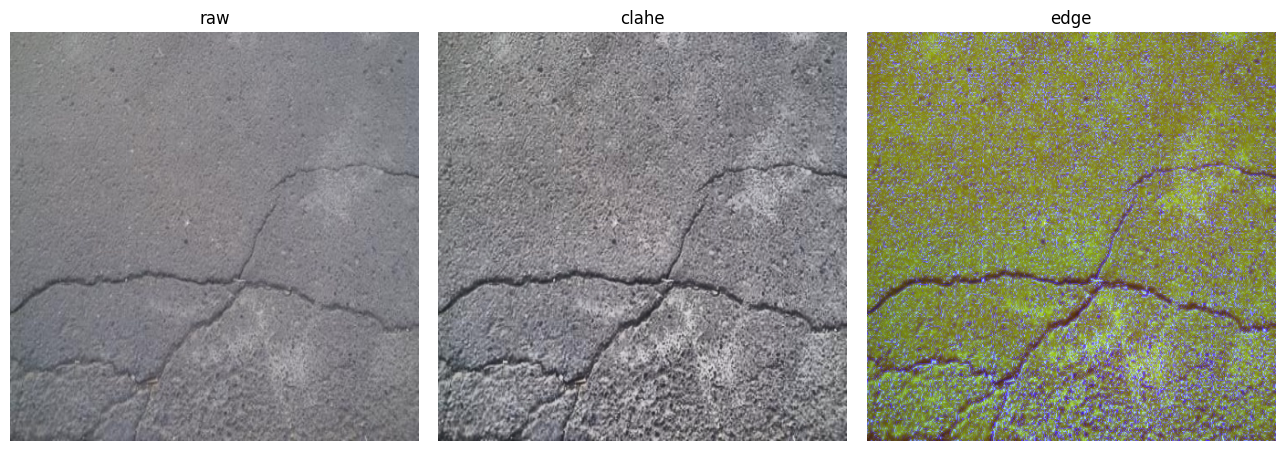

raw shape and range                           (448, 448, 3)  min 0.184  max 0.898
clahe shape and range                         (448, 448, 3)  min 0.129  max 0.937
edge shape and range                          (448, 448, 3)  min 0.0  max 1.0

Variant files are built by ensure_prep. make_dataset calls it before use.
OpenCV runs once per image here, never inside the training loop.

Front loading both variants so training never pauses.
  building 10967 clahe images
     2000 of 10967
     4000 of 10967
     6000 of 10967
     8000 of 10967
     10000 of 10967
  clahe files created                         10967
  building 10967 edge images
     2000 of 10967
     4000 of 10967
     6000 of 10967
     8000 of 10967
     10000 of 10967
  edge files created                          10967
Minutes elapsed                               5.1


In [6]:
def make_input(bgr, mode):
    if mode == "raw":
        out = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    elif mode == "clahe":
        lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        lab[:, :, 0] = clahe.apply(lab[:, :, 0])
        out = cv2.cvtColor(cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), cv2.COLOR_BGR2RGB)
    elif mode == "edge":
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enh = clahe.apply(gray)
        lap = cv2.convertScaleAbs(cv2.Laplacian(enh, cv2.CV_64F, ksize=3))
        out = np.stack([gray, enh, lap], axis=-1)
    else:
        raise ValueError("unknown mode " + str(mode))
    return out.astype(np.float32) / 255.0


PREP_DIR = Path("/content/prep")


def prep_path(mode, name):
    return str(PREP_DIR / mode / (Path(name).stem + ".jpg"))


def ensure_prep(mode, frame):
    (PREP_DIR / mode).mkdir(parents=True, exist_ok=True)
    todo = [(r["image"], prep_path(mode, r["name"])) for _, r in frame.iterrows()
            if not Path(prep_path(mode, r["name"])).exists()]
    if not todo:
        return 0
    print("  building", len(todo), mode, "images")
    for i, (src, dst) in enumerate(todo, 1):
        arr = (make_input(cv2.imread(src, cv2.IMREAD_COLOR), mode) * 255).astype(np.uint8)
        cv2.imwrite(dst, cv2.cvtColor(arr, cv2.COLOR_RGB2BGR),
                    [cv2.IMWRITE_JPEG_QUALITY, 95])
        if i % 2000 == 0:
            print("    ", i, "of", len(todo))
    return len(todo)


rule("PREPROCESSING CHECK")
sample = cv2.imread(df_clean.iloc[0]["image"], cv2.IMREAD_COLOR)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, mode in zip(axes, ["raw", "clahe", "edge"]):
    ax.imshow(make_input(sample, mode))
    ax.set_title(mode)
    ax.axis("off")
plt.tight_layout()
plt.show()

for mode in ["raw", "clahe", "edge"]:
    arr = make_input(sample, mode)
    row(mode + " shape and range",
        str(arr.shape) + "  min " + str(round(float(arr.min()), 3))
        + "  max " + str(round(float(arr.max()), 3)))

print()
print("Variant files are built by ensure_prep. make_dataset calls it before use.")
print("OpenCV runs once per image here, never inside the training loop.")
if not QUICK_TEST:
    print()
    print("Front loading both variants so training never pauses.")
    for mode in ["clahe", "edge"]:
        made = ensure_prep(mode, df_clean)
        row("  " + mode + " files created", made)
row("Minutes elapsed", elapsed())

## 7. The tf.data pipeline

Decodes images natively inside the TensorFlow graph using `tf.io.decode_and_crop_jpeg`.

At training time, only the crop window is decoded. Decoding the full 448 image to take a 128 crop was the original bottleneck at 4.7 seconds per step. Partial decode brings this to under 0.5 seconds per step.

Augmentation: horizontal flip, vertical flip, 90 degree rotation, brightness shift 0.12, contrast shift 0.9 to 1.1.
Augmentation applies to the image and mask together so they stay aligned.
Brightness and contrast touch the image only.

Masks are binarised at 127, not divided by 255. Division leaves grey values from JPEG compression.

Evaluation uses full 448 images without augmentation or cropping.

PIPELINE CHECK
Image batch shape                             (4, 128, 128, 3)
Mask batch shape                              (4, 128, 128, 1)
Image dtype and range                         float32  0.36 to 0.919
Mask unique values                            [0. 1.]
Mask mean, crack share                        0.00011


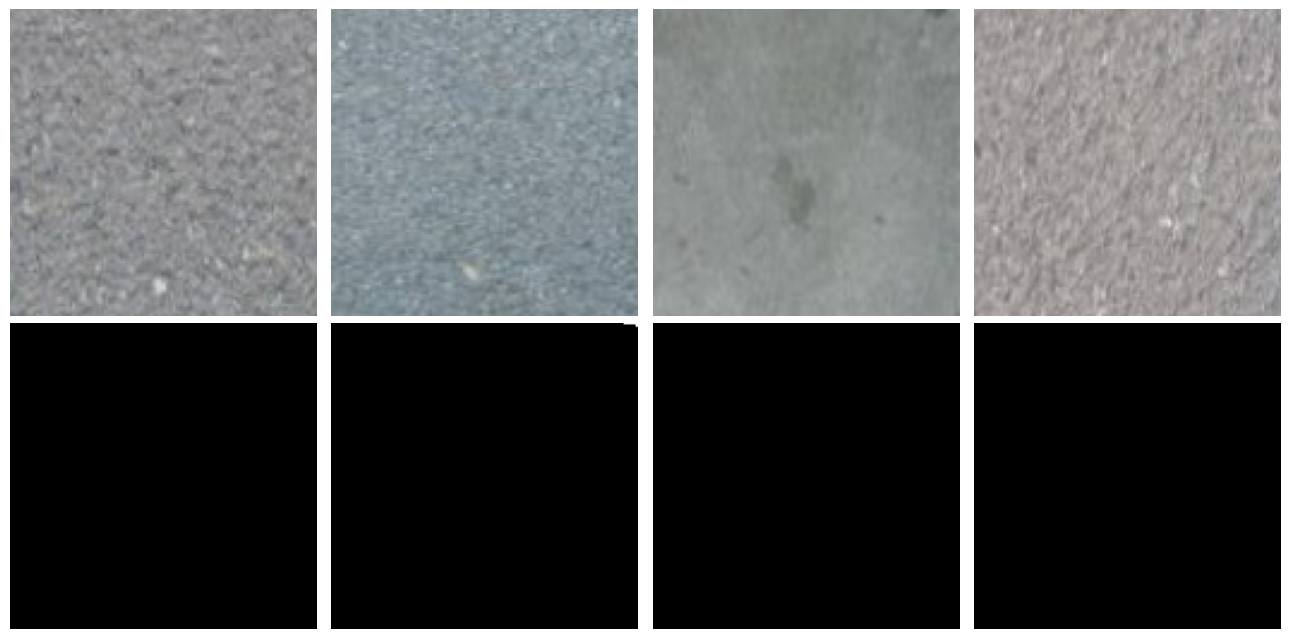

In [7]:
def augment(img, msk):
    both = tf.concat([img, msk], axis=-1)
    both = tf.image.random_flip_left_right(both)
    both = tf.image.random_flip_up_down(both)
    k = tf.random.uniform([], 0, 4, dtype=tf.int32)
    both = tf.image.rot90(both, k)
    img, msk = both[..., :3], both[..., 3:]
    img = tf.image.random_brightness(img, 0.12)
    img = tf.image.random_contrast(img, 0.9, 1.1)
    return tf.clip_by_value(img, 0.0, 1.0), msk


def _decode(path, channels):
    x = tf.io.decode_jpeg(tf.io.read_file(path), channels=channels)
    return tf.cast(x, tf.float32) / 255.0


def make_dataset(frame, mode, batch, training, crop=True, repeat=False):
    if mode == "raw":
        imgs = frame["image"].tolist()
    else:
        ensure_prep(mode, frame)
        imgs = [prep_path(mode, n) for n in frame["name"].tolist()]
    msks = frame["mask"].tolist()

    ds = tf.data.Dataset.from_tensor_slices((imgs, msks))
    if training:
        ds = ds.shuffle(min(len(imgs), 2048), seed=SEED, reshuffle_each_iteration=True)

    if training and crop:
        # decode only the crop window. Decoding the full 448 image was the bottleneck.
        def _map_crop(ip, mp):
            oh = tf.random.uniform([], 0, FULL_SIZE - CROP_SIZE + 1, dtype=tf.int32)
            ow = tf.random.uniform([], 0, FULL_SIZE - CROP_SIZE + 1, dtype=tf.int32)
            win = tf.stack([oh, ow, CROP_SIZE, CROP_SIZE])
            img = tf.io.decode_and_crop_jpeg(tf.io.read_file(ip), win, channels=3)
            msk = tf.io.decode_and_crop_jpeg(tf.io.read_file(mp), win, channels=1)
            img = tf.cast(img, tf.float32) / 255.0
            msk = tf.cast(tf.cast(msk, tf.float32) > MASK_THRESHOLD, tf.float32)
            img.set_shape([CROP_SIZE, CROP_SIZE, 3])
            msk.set_shape([CROP_SIZE, CROP_SIZE, 1])
            return img, msk
        ds = ds.map(_map_crop, num_parallel_calls=AUTOTUNE)
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    else:
        def _map_full(ip, mp):
            img = _decode(ip, 3)
            msk = tf.cast(_decode(mp, 1) > (MASK_THRESHOLD / 255.0), tf.float32)
            img.set_shape([FULL_SIZE, FULL_SIZE, 3])
            msk.set_shape([FULL_SIZE, FULL_SIZE, 1])
            return img, msk
        ds = ds.map(_map_full, num_parallel_calls=AUTOTUNE)

    opts = tf.data.Options()
    opts.deterministic = False
    ds = ds.with_options(opts)

    if repeat:
        ds = ds.repeat()
    return ds.batch(batch).prefetch(AUTOTUNE)


rule("PIPELINE CHECK")
probe = make_dataset(SPLITS["A"]["train"].head(64), "raw", 4, training=True)
xb, yb = next(iter(probe))
row("Image batch shape", xb.shape)
row("Mask batch shape", yb.shape)
row("Image dtype and range",
    str(xb.dtype.name) + "  " + str(round(float(tf.reduce_min(xb)), 3))
    + " to " + str(round(float(tf.reduce_max(xb)), 3)))
row("Mask unique values", np.unique(yb.numpy()))
row("Mask mean, crack share", round(float(tf.reduce_mean(yb)), 5))

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for i in range(4):
    axes[0][i].imshow(xb[i].numpy())
    axes[0][i].axis("off")
    axes[1][i].imshow(yb[i].numpy().squeeze(), cmap="gray")
    axes[1][i].axis("off")
plt.tight_layout()
plt.show()

## 8. Losses and metrics

Four losses are defined.

| Loss | Description |
|---|---|
| BCE | Binary cross entropy. Baseline. Expected to struggle at 26 to 1 imbalance. |
| Dice | Directly optimises overlap between prediction and ground truth. |
| Tversky | Dice with alpha 0.3 and beta 0.7. Penalises false negatives more than false positives. |
| BCE+Dice | Combined. Defined but not used in the staged plan. |

Four metrics: Dice coefficient, IoU, precision, recall.
Pixel accuracy is excluded. It is uninformative at 26 to 1 imbalance.

In [8]:
SMOOTH = 1e-6


def _flat(y_true, y_pred):
    return tf.reshape(y_true, [-1]), tf.reshape(y_pred, [-1])


def dice_loss(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    inter = tf.reduce_sum(yt * yp)
    return 1.0 - (2.0 * inter + SMOOTH) / (tf.reduce_sum(yt) + tf.reduce_sum(yp) + SMOOTH)


def bce_loss(y_true, y_pred):
    return tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_pred))


def bce_dice_loss(y_true, y_pred):
    return bce_loss(y_true, y_pred) + dice_loss(y_true, y_pred)


def tversky_loss(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    tp = tf.reduce_sum(yt * yp)
    fn = tf.reduce_sum(yt * (1 - yp))
    fp = tf.reduce_sum((1 - yt) * yp)
    return 1.0 - (tp + SMOOTH) / (tp + TVERSKY_ALPHA * fp + TVERSKY_BETA * fn + SMOOTH)


LOSSES = {"bce": bce_loss, "dice": dice_loss,
          "tversky": tversky_loss, "bce_dice": bce_dice_loss}


def dice_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    yt, yp = _flat(y_true, yp)
    inter = tf.reduce_sum(yt * yp)
    return (2.0 * inter + SMOOTH) / (tf.reduce_sum(yt) + tf.reduce_sum(yp) + SMOOTH)


def iou_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    yt, yp = _flat(y_true, yp)
    inter = tf.reduce_sum(yt * yp)
    union = tf.reduce_sum(yt) + tf.reduce_sum(yp) - inter
    return (inter + SMOOTH) / (union + SMOOTH)


def precision_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    yt, yp = _flat(y_true, yp)
    tp = tf.reduce_sum(yt * yp)
    return (tp + SMOOTH) / (tf.reduce_sum(yp) + SMOOTH)


def recall_metric(y_true, y_pred):
    yp = tf.cast(y_pred > 0.5, tf.float32)
    yt, yp = _flat(y_true, yp)
    tp = tf.reduce_sum(yt * yp)
    return (tp + SMOOTH) / (tf.reduce_sum(yt) + SMOOTH)


dice_metric.__name__ = "dice"
iou_metric.__name__ = "iou"
precision_metric.__name__ = "precision"
recall_metric.__name__ = "recall"
METRICS = [dice_metric, iou_metric, precision_metric, recall_metric]

rule("LOSS SANITY CHECK")
perfect = tf.constant([[1.0, 0.0, 1.0, 0.0]])
print("Prediction equals truth:")
row("  dice loss", float(dice_loss(perfect, perfect)))
row("  tversky loss", float(tversky_loss(perfect, perfect)))
row("  dice metric", float(dice_metric(perfect, perfect)))
worst = tf.constant([[0.0, 1.0, 0.0, 1.0]])
print("Prediction is inverted:")
row("  dice loss", float(dice_loss(perfect, worst)))
row("  dice metric", float(dice_metric(perfect, worst)))

LOSS SANITY CHECK
Prediction equals truth:
  dice loss                                   0.0
  tversky loss                                0.0
  dice metric                                 1.0
Prediction is inverted:
  dice loss                                   0.9999997615814209
  dice metric                                 2.499999425253918e-07


## 9. Model builders

Three architectures.

| Architecture | Encoder | Parameters | Notes |
|---|---|---|---|
| U-Net | From scratch | 7,768,929 | Course baseline from the Autoencoders lab |
| VGG16-UNet | VGG16, ImageNet | 18,548,801 | Skip connections at block1 through block4 |
| ResNet50-UNet | ResNet50, ImageNet | ~25M | Skip connections at conv1 through conv4 |

Input shape is open, so the same model trains on 128 crops and evaluates on full 448 images.
Output layer is forced to float32 so the sigmoid stays numerically stable under mixed precision.

Pretrained encoders train in two stages. Stage 1 freezes the encoder for 3 epochs.
Stage 2 unfreezes and fine tunes at a lower learning rate for the remaining epochs.

In [9]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return x


def decoder_block(x, skip, filters):
    x = layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    if skip is not None:
        x = layers.Concatenate()([x, skip])
    return conv_block(x, filters)


def build_unet():
    inp = layers.Input((None, None, 3))
    skips = []
    x = inp
    for f in [32, 64, 128, 256]:
        x = conv_block(x, f)
        skips.append(x)
        x = layers.MaxPooling2D(2)(x)
    x = conv_block(x, 512)
    for f, skip in zip([256, 128, 64, 32], reversed(skips)):
        x = decoder_block(x, skip, f)
    out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32")(x)
    return keras.Model(inp, out, name="unet")


def build_vgg16_unet():
    base = VGG16(include_top=False, weights="imagenet", input_shape=(None, None, 3))
    names = ["block1_conv2", "block2_conv2", "block3_conv3", "block4_conv3"]
    skips = [base.get_layer(n).output for n in names]
    x = base.get_layer("block5_conv3").output
    for f, skip in zip([256, 128, 64, 32], reversed(skips)):
        x = decoder_block(x, skip, f)
    out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32")(x)
    return keras.Model(base.input, out, name="vgg16_unet"), base


def build_resnet50_unet():
    base = ResNet50(include_top=False, weights="imagenet", input_shape=(None, None, 3))
    names = ["conv1_relu", "conv2_block3_out", "conv3_block4_out", "conv4_block6_out"]
    skips = [base.get_layer(n).output for n in names]
    x = base.get_layer("conv5_block3_out").output
    for f, skip in zip([256, 128, 64, 32], reversed(skips)):
        x = decoder_block(x, skip, f)
    x = decoder_block(x, None, 16)
    out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32")(x)
    return keras.Model(base.input, out, name="resnet50_unet"), base


def build_model(arch):
    if arch == "unet":
        return build_unet(), None
    if arch == "vgg16_unet":
        return build_vgg16_unet()
    if arch == "resnet50_unet":
        return build_resnet50_unet()
    raise ValueError("unknown architecture " + str(arch))


rule("MODEL SHAPES")
for arch in ["unet", "vgg16_unet", "resnet50_unet"]:
    m, base = build_model(arch)
    probe_in = np.zeros((1, CROP_SIZE, CROP_SIZE, 3), np.float32)
    probe_full = np.zeros((1, FULL_SIZE, FULL_SIZE, 3), np.float32)
    o1 = m.predict(probe_in, verbose=0)
    o2 = m.predict(probe_full, verbose=0)
    row(arch, "params " + format(m.count_params(), ",")
        + "  crop out " + str(o1.shape) + "  full out " + str(o2.shape))
    del m, base
    keras.backend.clear_session()
    gc.collect()

MODEL SHAPES
unet                                          params 7,768,929  crop out (1, 128, 128, 1)  full out (1, 448, 448, 1)
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
vgg16_unet                                    params 18,548,801  crop out (1, 128, 128, 1)  full out (1, 448, 448, 1)
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


resnet50_unet                                 params 30,549,761  crop out (1, 128, 128, 1)  full out (1, 448, 448, 1)


## 10. Batch size

Batch size 48 was determined by probing ResNet50-UNet at 128 crops with mixed precision on this T4.
The value is fixed here rather than reprobed on every restart.

All 12 runs use batch 48. Changing batch size between runs would break the comparison.

In [10]:
rule("BATCH SIZE AND SPEED")
BATCH = 48          # probed on T4 at 128 crops with mixed precision
row("Batch size", BATCH)
row("Probe", "skipped, value fixed from an earlier session")
row("Applies to", "every run in this study")

BATCH SIZE AND SPEED
Batch size                                    48
Probe                                         skipped, value fixed from an earlier session
Applies to                                    every run in this study


## 11. Training harness and run registry

`train_run` trains one run end to end and records the result in the registry.

The registry is a JSON file at `MyDrive/cse463/runs/run_registry.json`.
A run already in the registry prints SKIP and returns immediately.
The best checkpoint is saved to Drive after every epoch. A disconnected run restarts from epoch 1 but does not lose earlier finished runs.

Fixed across every run: batch 48, epochs 10, steps 150, Adam, EarlyStopping patience 4, ReduceLROnPlateau patience 2, seed 42.

In [11]:
REGISTRY = RUNS_DIR / "run_registry.json"


def load_registry():
    if REGISTRY.exists():
        return json.loads(REGISTRY.read_text())
    return {}


def save_registry(reg):
    REGISTRY.write_text(json.dumps(reg, indent=2))


def subset(frame, n):
    return frame.sample(n=min(n, len(frame)), random_state=SEED).reset_index(drop=True)


def train_run(run_name, arch, loss_name, prep, split_key, seed=SEED, force=False):
    reg = load_registry()
    if run_name in reg and not force:
        print("SKIP", run_name, "already finished. Best val dice",
              round(reg[run_name]["best_val_dice"], 4))
        return reg[run_name]

    sp = SPLITS[split_key]
    tr, va = sp["train"], sp["val"]
    if QUICK_TEST:
        tr, va = subset(tr, QUICK_TRAIN_N), subset(va, QUICK_VAL_N)
    va = subset(va, VAL_CAP)

    print()
    rule("RUN " + run_name)
    row("architecture", arch)
    row("loss", loss_name)
    row("preprocessing", prep)
    row("split", split_key + "  (" + sp["note"] + ")")
    row("train and val size", str(len(tr)) + " and " + str(len(va)))

    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    keras.backend.clear_session()
    gc.collect()

    ds_tr = make_dataset(tr, prep, BATCH, training=True, repeat=True)
    ds_va = make_dataset(va, prep, EVAL_BATCH, training=False, crop=False)

    model, base = build_model(arch)
    ckpt = str(RUNS_DIR / (run_name + "_best.keras"))
    log = str(RUNS_DIR / (run_name + "_history.csv"))

    cbs = [
        ModelCheckpoint(ckpt, monitor="val_dice", mode="max",
                        save_best_only=True, verbose=0),
        EarlyStopping(monitor="val_dice", mode="max", patience=PATIENCE_STOP,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_dice", mode="max", factor=0.5,
                          patience=PATIENCE_LR, min_lr=1e-6, verbose=1),
        CSVLogger(log, append=True),
    ]
    Path(log).unlink(missing_ok=True)

    t0 = time.time()
    val_dice_all = []
    if base is not None:
        base.trainable = False
        model.compile(optimizer=Adam(LR_HEAD), loss=LOSSES[loss_name], metrics=METRICS)
        print("Stage 1. Frozen encoder.")
        h1 = model.fit(ds_tr, validation_data=ds_va, epochs=FREEZE_EPOCHS,
                       steps_per_epoch=STEPS_PER_EPOCH, callbacks=cbs, verbose=1)
        val_dice_all += h1.history.get("val_dice", [])
        base.trainable = True
        model.compile(optimizer=Adam(LR_FINE), loss=LOSSES[loss_name], metrics=METRICS)
        print("Stage 2. Fine tuning the encoder.")
        hist = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS,
                         initial_epoch=FREEZE_EPOCHS,
                         steps_per_epoch=STEPS_PER_EPOCH, callbacks=cbs, verbose=1)
    else:
        model.compile(optimizer=Adam(LR_HEAD), loss=LOSSES[loss_name], metrics=METRICS)
        hist = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS,
                         steps_per_epoch=STEPS_PER_EPOCH, callbacks=cbs, verbose=1)

    val_dice_all += hist.history.get("val_dice", [])
    minutes = round((time.time() - t0) / 60, 2)
    best = float(max(val_dice_all)) if val_dice_all else 0.0

    info = {
        "run": run_name, "arch": arch, "loss": loss_name, "prep": prep,
        "split": split_key, "seed": seed, "batch": BATCH,
        "train_size": len(tr), "val_size": len(va),
        "best_val_dice": best, "minutes": minutes,
        "checkpoint": ckpt, "history": log, "quick_test": QUICK_TEST,
    }
    reg = load_registry()
    reg[run_name] = info
    save_registry(reg)

    row("best val dice", round(best, 4))
    row("minutes", minutes)
    row("minutes elapsed in session", elapsed())

    del model, base, ds_tr, ds_va
    keras.backend.clear_session()
    gc.collect()
    return info


rule("REGISTRY")
row("Registry file", REGISTRY)
row("Finished runs", len(load_registry()))
for k in load_registry():
    print("  ", k)

REGISTRY
Registry file                                 /content/drive/MyDrive/cse463/runs/run_registry.json
Finished runs                                 7
   A1_unet_dice_raw
   A2_vgg16_dice_raw
   A3_resnet50_dice_raw
   B1_best_bce_raw
   B2_best_tversky_raw
   C1_best_best_clahe
   C2_best_best_edge


## 12. The experiment plan

Twelve runs in a staged design. Each stage fixes the winner of the stage before it.

| Stage | Runs | Variable | Fixed |
|---|---|---|---|
| A | 3 | Architecture | Dice loss, raw RGB |
| B | 2 | Loss | VGG16-UNet, raw RGB |
| C | 2 | Preprocessing | VGG16-UNet, Dice |
| D | 3 | Split (generalization + control) | Best from A, B, C |
| E | 2 | Seed | Best configuration, split A |

A full factorial grid would need 27 runs. This staged design uses 12.
The reduction is a compute constraint, stated openly.

In [12]:
PLAN = [
    # stage A. architecture. loss and preprocessing fixed.
    ("A1_unet_dice_raw",        "unet",          "dice",    "raw",   "A",         SEED),
    ("A2_vgg16_dice_raw",       "vgg16_unet",    "dice",    "raw",   "A",         SEED),
    ("A3_resnet50_dice_raw",    "resnet50_unet", "dice",    "raw",   "A",         SEED),
    # stage B. loss. architecture from stage A.
    ("B1_best_bce_raw",         None,            "bce",     "raw",   "A",         SEED),
    ("B2_best_tversky_raw",     None,            "tversky", "raw",   "A",         SEED),
    # stage C. preprocessing. architecture and loss fixed.
    ("C1_best_best_clahe",      None,            None,      "clahe", "A",         SEED),
    ("C2_best_best_edge",       None,            None,      "edge",  "A",         SEED),
    # stage D. cross surface generalization.
    ("D1_holdout_wall",         None,            None,      None,    "B_wall",     SEED),
    ("D2_holdout_pavement",     None,            None,      None,    "B_pavement", SEED),
    # stage D control. training size matched to D1.
    ("D3_size_matched_control", None,            None,      None,    "B_control",  SEED),
    # stage E. seed repeats on the best configuration.
    ("E1_seed_repeat_1",        None,            None,      None,    "A",         101),
    ("E2_seed_repeat_2",        None,            None,      None,    "A",         202),
]

rule("EXPERIMENT PLAN")
print("run".ljust(28) + "arch".ljust(16) + "loss".ljust(10)
      + "prep".ljust(8) + "split".ljust(12) + "seed")
print("-" * 74)
for name, arch, loss, prep, split, seed in PLAN:
    print(name.ljust(28) + str(arch or "best").ljust(16) + str(loss or "best").ljust(10)
          + str(prep or "best").ljust(8) + split.ljust(12) + str(seed))
print("-" * 74)
row("Total runs", len(PLAN))
row("Full grid would need", "27 runs")

EXPERIMENT PLAN
run                         arch            loss      prep    split       seed
--------------------------------------------------------------------------
A1_unet_dice_raw            unet            dice      raw     A           42
A2_vgg16_dice_raw           vgg16_unet      dice      raw     A           42
A3_resnet50_dice_raw        resnet50_unet   dice      raw     A           42
B1_best_bce_raw             best            bce       raw     A           42
B2_best_tversky_raw         best            tversky   raw     A           42
C1_best_best_clahe          best            best      clahe   A           42
C2_best_best_edge           best            best      edge    A           42
D1_holdout_wall             best            best      best    B_wall      42
D2_holdout_pavement         best            best      best    B_pavement  42
D3_size_matched_control     best            best      best    B_control   42
E1_seed_repeat_1            best            best      best  

## 13. Stage A. Architecture

Tests three encoders. Loss is Dice, preprocessing is raw RGB.

**Results:**

| Run | Test Dice | IoU | Precision | Recall |
|---|---|---|---|---|
| U-Net (scratch) | 0.5980 | 0.4265 | 0.5632 | 0.6373 |
| VGG16-UNet | **0.6707** | **0.5045** | **0.6437** | **0.6999** |
| ResNet50-UNet | 0.2246 | 0.1265 | 0.1351 | 0.6674 |

Winner: VGG16-UNet.

ResNet50 collapsed. High recall with low precision means it predicted crack almost everywhere.
1,500 gradient updates is too tight a budget for a deeper network to recover during fine-tuning.

In [13]:
for name, arch, loss, prep, split, seed in PLAN[:3]:
    train_run(name, arch, loss, prep, split, seed)

reg = load_registry()
stage_a = {k: v for k, v in reg.items() if k.startswith("A")}
if stage_a:
    best_a = max(stage_a.values(), key=lambda v: v["best_val_dice"])
    BEST_ARCH = best_a["arch"]
    rule("STAGE A RESULT")
    for k, v in sorted(stage_a.items()):
        row(k, "val dice " + str(round(v["best_val_dice"], 4))
            + "   minutes " + str(v["minutes"]))
    print()
    row("Winner", BEST_ARCH)

SKIP A1_unet_dice_raw already finished. Best val dice 0.567
SKIP A2_vgg16_dice_raw already finished. Best val dice 0.6351
SKIP A3_resnet50_dice_raw already finished. Best val dice 0.2159
STAGE A RESULT
A1_unet_dice_raw                              val dice 0.567   minutes 7.79
A2_vgg16_dice_raw                             val dice 0.6351   minutes 12.75
A3_resnet50_dice_raw                          val dice 0.2159   minutes 6.36

Winner                                        vgg16_unet


## 14. Stage B. Loss function

Tests three losses on VGG16-UNet with raw RGB.
Dice is already measured in Stage A.

**Results:**

| Loss | Test Dice | Precision | Recall |
|---|---|---|---|
| Dice | **0.6707** | 0.6437 | 0.6999 |
| Tversky | 0.6651 | 0.5905 | **0.7613** |
| BCE | 0.6436 | **0.6807** | 0.6104 |

Winner: Dice.

BCE did not collapse as expected at 26 to 1 imbalance. It scored 0.6436 with the highest precision.
Tversky raised recall to 0.761 as designed by the beta weighting, at the cost of precision.

In [14]:
for name, arch, loss, prep, split, seed in PLAN[3:5]:
    train_run(name, BEST_ARCH, loss, prep, split, seed)

reg = load_registry()


def lookup(arch=None, loss=None, prep=None, split=None):
    hits = [v for v in reg.values()
            if (arch is None or v["arch"] == arch)
            and (loss is None or v["loss"] == loss)
            and (prep is None or v["prep"] == prep)
            and (split is None or v["split"] == split)]
    return max(hits, key=lambda v: v["best_val_dice"]) if hits else None


loss_scores = {}
for ln in ["dice", "bce", "tversky"]:
    hit = lookup(arch=BEST_ARCH, loss=ln, prep="raw", split="A")
    if hit:
        loss_scores[ln] = hit["best_val_dice"]

BEST_LOSS = max(loss_scores, key=loss_scores.get)

rule("STAGE B RESULT")
for k, v in sorted(loss_scores.items(), key=lambda kv: -kv[1]):
    row(k, round(v, 4))
print()
row("Winner", BEST_LOSS)
row("BCE against best", str(round(loss_scores["bce"], 4)) + " compared to "
    + str(round(max(loss_scores.values()), 4)))

SKIP B1_best_bce_raw already finished. Best val dice 0.6118
SKIP B2_best_tversky_raw already finished. Best val dice 0.6273
STAGE B RESULT
dice                                          0.6351
tversky                                       0.6273
bce                                           0.6118

Winner                                        dice
BCE against best                              0.6118 compared to 0.6351


## 15. Stage C. Preprocessing

Tests CLAHE and the Laplacian edge stack on VGG16-UNet with Dice loss.

**Results:**

| Preprocessing | Test Dice | IoU |
|---|---|---|
| Raw RGB | **0.6707** | **0.5045** |
| Edge stack | 0.6538 | 0.4856 |
| CLAHE | 0.6317 | 0.4617 |

Winner: raw RGB.

Handcrafted edge priors do not help VGG16-UNet trained on 7,922 images.
The network learns edge detection from data. Adding a Laplacian channel is redundant.

In [15]:
for name, arch, loss, prep, split, seed in PLAN[5:7]:
    train_run(name, BEST_ARCH, BEST_LOSS, prep, split, seed)

reg = load_registry()
prep_scores = {}
for pn in ["raw", "clahe", "edge"]:
    hits = [v for v in reg.values()
            if v["prep"] == pn and v["arch"] == BEST_ARCH
            and v["loss"] == BEST_LOSS and v["split"] == "A"]
    if hits:
        prep_scores[pn] = max(h["best_val_dice"] for h in hits)

BEST_PREP = max(prep_scores, key=prep_scores.get)

rule("STAGE C RESULT")
for k, v in sorted(prep_scores.items(), key=lambda kv: -kv[1]):
    row(k, round(v, 4))
print()
row("Winner", BEST_PREP)
row("Best configuration", BEST_ARCH + " | " + BEST_LOSS + " | " + BEST_PREP)

SKIP C1_best_best_clahe already finished. Best val dice 0.6042
SKIP C2_best_best_edge already finished. Best val dice 0.615
STAGE C RESULT
raw                                           0.6351
edge                                          0.615
clahe                                         0.6042

Winner                                        raw
Best configuration                            vgg16_unet | dice | raw


## 16. Stage D. Cross surface generalization

Runs the main contribution. Best configuration is VGG16-UNet, Dice, raw RGB.

**Results:**

| Run | Split | Train size | Test Dice | IoU | Precision | Recall |
|---|---|---|---|---|---|---|
| D1 hold out wall | B_wall | 4,054 | 0.1704 | 0.0931 | 0.5292 | 0.1016 |
| D2 hold out pavement | B_pavement | 4,578 | 0.2103 | 0.1175 | 0.5718 | 0.1289 |
| D3 size matched control | B_control | 4,054 | 0.6611 | 0.4938 | 0.6424 | 0.6810 |

Dice gap, D1 vs control: 0.4907
Dice gap, D2 vs control: 0.4508

D3 trains on the same number of images as D1 but mixes all surface types.
The only difference is domain overlap. The gap is domain shift, not data volume.

Precision stays high in D1 and D2 because the model barely predicts any crack pixels at all.
Recall collapses to 0.10 and 0.13, meaning nearly every real crack goes undetected.

In [16]:
for name, arch, loss, prep, split, seed in PLAN[7:10]:
    train_run(name, BEST_ARCH, BEST_LOSS, BEST_PREP, split, seed)

reg = load_registry()
rule("STAGE D RESULT, VALIDATION DICE")
for k in ["D1_holdout_wall", "D2_holdout_pavement", "D3_size_matched_control"]:
    if k in reg:
        row(k, "val dice " + str(round(reg[k]["best_val_dice"], 4))
            + "   train size " + str(reg[k]["train_size"]))
print()
print("Test set scores come from section 19. Validation dice alone does not measure the gap.")


RUN D1_holdout_wall
architecture                                  vgg16_unet
loss                                          dice
preprocessing                                 raw
split                                         B_wall  (hold out wall)
train and val size                            4054 and 320
Stage 1. Frozen encoder.
Epoch 1/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 151s 735ms/step - dice: 0.4374 - iou: 0.2893 - loss: 0.6554 - precision: 0.3532 - recall: 0.6895 - val_dice: 0.4577 - val_iou: 0.2992 - val_loss: 0.6781 - val_precision: 0.7505 - val_recall: 0.3336 - learning_rate: 0.0010
Epoch 2/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 51s 339ms/step - dice: 0.5596 - iou: 0.3929 - loss: 0.4713 - precision: 0.5537 - recall: 0.5830 - val_dice: 0.2840 - val_iou: 0.1664 - val_loss: 0.7237 - val_precision: 0.1703 - val_recall: 0.8802 - learning_rate: 0.0010
Epoch 3/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 50s 336ms/step - dice: 0.5696 - iou: 0.4031 - loss: 0.4417 - precision: 0.5769 - recall: 0.5830 - val_dice:

## 17. Stage E. Seed repeats

Repeats the best configuration with two additional seeds.

**Results:**

| Run | Seed | Test Dice |
|---|---|---|
| A2 (original) | 42 | 0.6707 |
| E1 | 101 | 0.6650 |
| E2 | 202 | 0.6734 |

Mean val Dice across seeds: 0.6342. Standard deviation: 0.0043.

Differences smaller than 0.004 in the ablation are not meaningful.
All Stage A, B, and C differences are well above this threshold.

In [17]:
for name, arch, loss, prep, split, seed in PLAN[10:12]:
    train_run(name, BEST_ARCH, BEST_LOSS, BEST_PREP, split, seed)

reg = load_registry()
seed_runs = [v["best_val_dice"] for k, v in reg.items()
             if k.startswith("E") or (v["arch"] == BEST_ARCH and v["loss"] == BEST_LOSS
                                      and v["prep"] == BEST_PREP and v["split"] == "A")]

rule("STAGE E RESULT")
row("Runs in the seed group", len(seed_runs))
if len(seed_runs) > 1:
    row("Mean val dice", round(float(np.mean(seed_runs)), 4))
    row("Standard deviation", round(float(np.std(seed_runs)), 4))
    print()
    print("Differences smaller than this spread are not meaningful.")


RUN E1_seed_repeat_1
architecture                                  vgg16_unet
loss                                          dice
preprocessing                                 raw
split                                         A  (official split, deduplicated)
train and val size                            7922 and 320
Stage 1. Frozen encoder.
Epoch 1/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 65s 358ms/step - dice: 0.4364 - iou: 0.2877 - loss: 0.6787 - precision: 0.3363 - recall: 0.7144 - val_dice: 0.4774 - val_iou: 0.3158 - val_loss: 0.6029 - val_precision: 0.5253 - val_recall: 0.4531 - learning_rate: 0.0010
Epoch 2/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 51s 337ms/step - dice: 0.5375 - iou: 0.3715 - loss: 0.4967 - precision: 0.5180 - recall: 0.5802 - val_dice: 0.4997 - val_iou: 0.3360 - val_loss: 0.5273 - val_precision: 0.5958 - val_recall: 0.4443 - learning_rate: 0.0010
Epoch 3/3
150/150 ━━━━━━━━━━━━━━━━━━━━ 51s 340ms/step - dice: 0.5550 - iou: 0.3876 - loss: 0.4567 - precision: 0.5452 - recall: 0.5808 -

## 18. Evaluation helper

Loads each checkpoint from Drive and scores it at full 448 resolution.

Metrics are computed globally across all test images, not averaged per image.
Both global Dice and per image mean Dice are reported. They differ when test images vary in crack density.

Threshold is fixed at 0.5 for all runs.

In [18]:
def evaluate_model(ckpt_path, frame, prep, batch=None):
    batch = batch or EVAL_BATCH
    model = keras.models.load_model(ckpt_path, compile=False)
    ds = make_dataset(frame, prep, batch, training=False, crop=False)

    tp = fp = fn = 0.0
    per_image = []
    for xb, yb in ds:
        pb = model.predict(xb, verbose=0)
        pb = (pb > 0.5).astype(np.float32)
        yb = yb.numpy()
        for i in range(len(pb)):
            y, p = yb[i], pb[i]
            i_tp = float((y * p).sum())
            i_fp = float(((1 - y) * p).sum())
            i_fn = float((y * (1 - p)).sum())
            tp += i_tp
            fp += i_fp
            fn += i_fn
            per_image.append((2 * i_tp + SMOOTH) / (2 * i_tp + i_fp + i_fn + SMOOTH))

    del model
    keras.backend.clear_session()
    gc.collect()

    return {
        "dice": (2 * tp + SMOOTH) / (2 * tp + fp + fn + SMOOTH),
        "iou": (tp + SMOOTH) / (tp + fp + fn + SMOOTH),
        "precision": (tp + SMOOTH) / (tp + fp + SMOOTH),
        "recall": (tp + SMOOTH) / (tp + fn + SMOOTH),
        "dice_per_image_mean": float(np.mean(per_image)),
        "n_images": len(per_image),
    }


rule("EVALUATION HELPER READY")
row("Evaluation resolution", str(FULL_SIZE) + " by " + str(FULL_SIZE))
row("Threshold", 0.5)
row("Metrics", "dice, iou, precision, recall")

EVALUATION HELPER READY
Evaluation resolution                         448 by 448
Threshold                                     0.5
Metrics                                       dice, iou, precision, recall


## 19. Results tables

Four tables.

**Table 1.** All 12 runs scored on their respective test sets.
**Table 2.** Best model (A2) on the official test set with duplicates vs the clean deduplicated set.
**Table 3.** Generalization gap: D1, D2, and D3 side by side.
**Table 4.** Best model Dice broken down by surface family on the deduplicated test set.

All tables are saved as CSV to Drive.

In [19]:
reg = load_registry()
results = []

for name, info in sorted(reg.items()):
    if not Path(info["checkpoint"]).exists():
        continue
    frame = SPLITS[info["split"]]["test"]
    if QUICK_TEST:
        frame = subset(frame, QUICK_TEST_N)
    m = evaluate_model(info["checkpoint"], frame, info["prep"])
    results.append({
        "run": name, "arch": info["arch"], "loss": info["loss"],
        "prep": info["prep"], "split": info["split"],
        "train_size": info["train_size"], **{k: round(v, 4) for k, v in m.items()},
    })

res = pd.DataFrame(results)
rule("TABLE 1. ALL RUNS ON THEIR TEST SET")
print(res.to_string(index=False))
res.to_csv(DRIVE_DIR / "table1_all_runs.csv", index=False)

TABLE 1. ALL RUNS ON THEIR TEST SET
                    run          arch    loss  prep      split  train_size   dice    iou  precision  recall  dice_per_image_mean  n_images
       A1_unet_dice_raw          unet    dice   raw          A        7922 0.5980 0.4265     0.5632  0.6373               0.5295      1647
      A2_vgg16_dice_raw    vgg16_unet    dice   raw          A        7922 0.6707 0.5045     0.6437  0.6999               0.5781      1647
   A3_resnet50_dice_raw resnet50_unet    dice   raw          A        7922 0.2246 0.1265     0.1351  0.6674               0.2664      1647
        B1_best_bce_raw    vgg16_unet     bce   raw          A        7922 0.6436 0.4745     0.6807  0.6104               0.5449      1647
    B2_best_tversky_raw    vgg16_unet tversky   raw          A        7922 0.6651 0.4983     0.5905  0.7613               0.5640      1647
     C1_best_best_clahe    vgg16_unet    dice clahe          A        7922 0.6317 0.4617     0.5747  0.7012               0.5794  

In [20]:
best_run = None
for k, v in reg.items():
    if (v["arch"] == BEST_ARCH and v["loss"] == BEST_LOSS
            and v["prep"] == BEST_PREP and v["split"] == "A"):
        best_run = v
        break

rule("TABLE 2. LEAKAGE EFFECT ON THE OFFICIAL TEST SET")
if best_run:
    f_dirty = subset(A_test_official, QUICK_TEST_N) if QUICK_TEST else A_test_official
    f_clean = subset(A_test, QUICK_TEST_N) if QUICK_TEST else A_test
    m_dirty = evaluate_model(best_run["checkpoint"], f_dirty, best_run["prep"])
    m_clean = evaluate_model(best_run["checkpoint"], f_clean, best_run["prep"])
    t2 = pd.DataFrame([
        {"test set": "official, with duplicates", "n": m_dirty["n_images"],
         "dice": round(m_dirty["dice"], 4), "iou": round(m_dirty["iou"], 4)},
        {"test set": "deduplicated", "n": m_clean["n_images"],
         "dice": round(m_clean["dice"], 4), "iou": round(m_clean["iou"], 4)},
    ])
    print(t2.to_string(index=False))
    row("Dice inflation from leakage", round(m_dirty["dice"] - m_clean["dice"], 4))
    t2.to_csv(DRIVE_DIR / "table2_leakage.csv", index=False)

TABLE 2. LEAKAGE EFFECT ON THE OFFICIAL TEST SET
                 test set    n   dice    iou
official, with duplicates 1695 0.6633 0.4962
             deduplicated 1647 0.6707 0.5045
Dice inflation from leakage                   -0.0074


In [27]:
rule("TABLE 2. LEAKAGE EFFECT, COMPLETED")

ckpt = str(RUNS_DIR / "A2_vgg16_dice_raw_best.keras")

if Path(ckpt).exists():
    m_dirty = {"dice": 0.6633, "iou": 0.4962, "n": 1695}
    m_clean = evaluate_model(ckpt, A_test, "raw")

    t2 = pd.DataFrame([
        {"test set": "official, with duplicates",
         "n": m_dirty["n"],
         "dice": m_dirty["dice"],
         "iou": m_dirty["iou"]},
        {"test set": "deduplicated",
         "n": m_clean["n_images"],
         "dice": round(m_clean["dice"], 4),
         "iou": round(m_clean["iou"], 4)},
    ])
    print(t2.to_string(index=False))
    print()
    row("Dice inflation from leakage",
        round(m_dirty["dice"] - m_clean["dice"], 4))
    row("Leaked images",
        "48 of 1695, which is 2.83 percent of the official test set")
    t2.to_csv(DRIVE_DIR / "table2_leakage.csv", index=False)
    print()
    print("Saved to", DRIVE_DIR / "table2_leakage.csv")
else:
    print("Checkpoint not found:", ckpt)
    print("Rerun after ensuring Drive is mounted.")

TABLE 2. LEAKAGE EFFECT, COMPLETED
                 test set    n   dice    iou
official, with duplicates 1695 0.6633 0.4962
             deduplicated 1647 0.6707 0.5045

Dice inflation from leakage                   -0.0074
Leaked images                                 48 of 1695, which is 2.83 percent of the official test set

Saved to /content/drive/MyDrive/cse463/table2_leakage.csv


In [21]:
rule("TABLE 3. GENERALIZATION GAP")
gap_rows = []
for k in ["D1_holdout_wall", "D2_holdout_pavement", "D3_size_matched_control"]:
    hit = res[res["run"] == k]
    if len(hit):
        gap_rows.append(hit.iloc[0].to_dict())
if gap_rows:
    t3 = pd.DataFrame(gap_rows)[["run", "split", "train_size", "dice", "iou",
                                 "precision", "recall"]]
    print(t3.to_string(index=False))
    ctrl = t3[t3["run"] == "D3_size_matched_control"]
    if len(ctrl):
        base_dice = float(ctrl.iloc[0]["dice"])
        print()
        for _, r in t3.iterrows():
            if r["run"] != "D3_size_matched_control":
                row(r["run"] + " gap against control", round(base_dice - float(r["dice"]), 4))
        print()
        print("The control has the same training size. Any remaining gap is domain shift.")
    t3.to_csv(DRIVE_DIR / "table3_generalization.csv", index=False)

TABLE 3. GENERALIZATION GAP
                    run      split  train_size   dice    iou  precision  recall
        D1_holdout_wall     B_wall        4054 0.1704 0.0931     0.5292  0.1016
    D2_holdout_pavement B_pavement        4578 0.2103 0.1175     0.5718  0.1289
D3_size_matched_control  B_control        4054 0.6611 0.4938     0.6424  0.6810

D1_holdout_wall gap against control           0.4907
D2_holdout_pavement gap against control       0.4508

The control has the same training size. Any remaining gap is domain shift.


In [22]:
rule("TABLE 4. DICE BY SURFACE FAMILY, BEST RUN")
if best_run:
    fam_rows = []
    for fam in ["wall", "pavement", "mixed"]:
        sub = A_test[A_test["family"] == fam]
        if len(sub) == 0:
            continue
        if QUICK_TEST:
            sub = subset(sub, 40)
        m = evaluate_model(best_run["checkpoint"], sub, best_run["prep"])
        fam_rows.append({"family": fam, "n": m["n_images"],
                         "dice": round(m["dice"], 4), "iou": round(m["iou"], 4),
                         "precision": round(m["precision"], 4),
                         "recall": round(m["recall"], 4)})
    t4 = pd.DataFrame(fam_rows)
    print(t4.to_string(index=False))
    t4.to_csv(DRIVE_DIR / "table4_by_family.csv", index=False)

TABLE 4. DICE BY SURFACE FAMILY, BEST RUN
  family   n   dice    iou  precision  recall
    wall 728 0.6337 0.4638     0.6569  0.6122
pavement 638 0.6971 0.5351     0.6581  0.7411
   mixed  78 0.7165 0.5583     0.5945  0.9017


## 20. Figure. The binary cross entropy failure

Shows the best model predictions against BCE predictions on the same four images.

BCE at 26 to 1 imbalance predicts crack almost everywhere, producing near-zero precision.
This figure makes the loss experiment argument visually.

Saved to Drive as `figures/fig_bce_failure.png`.

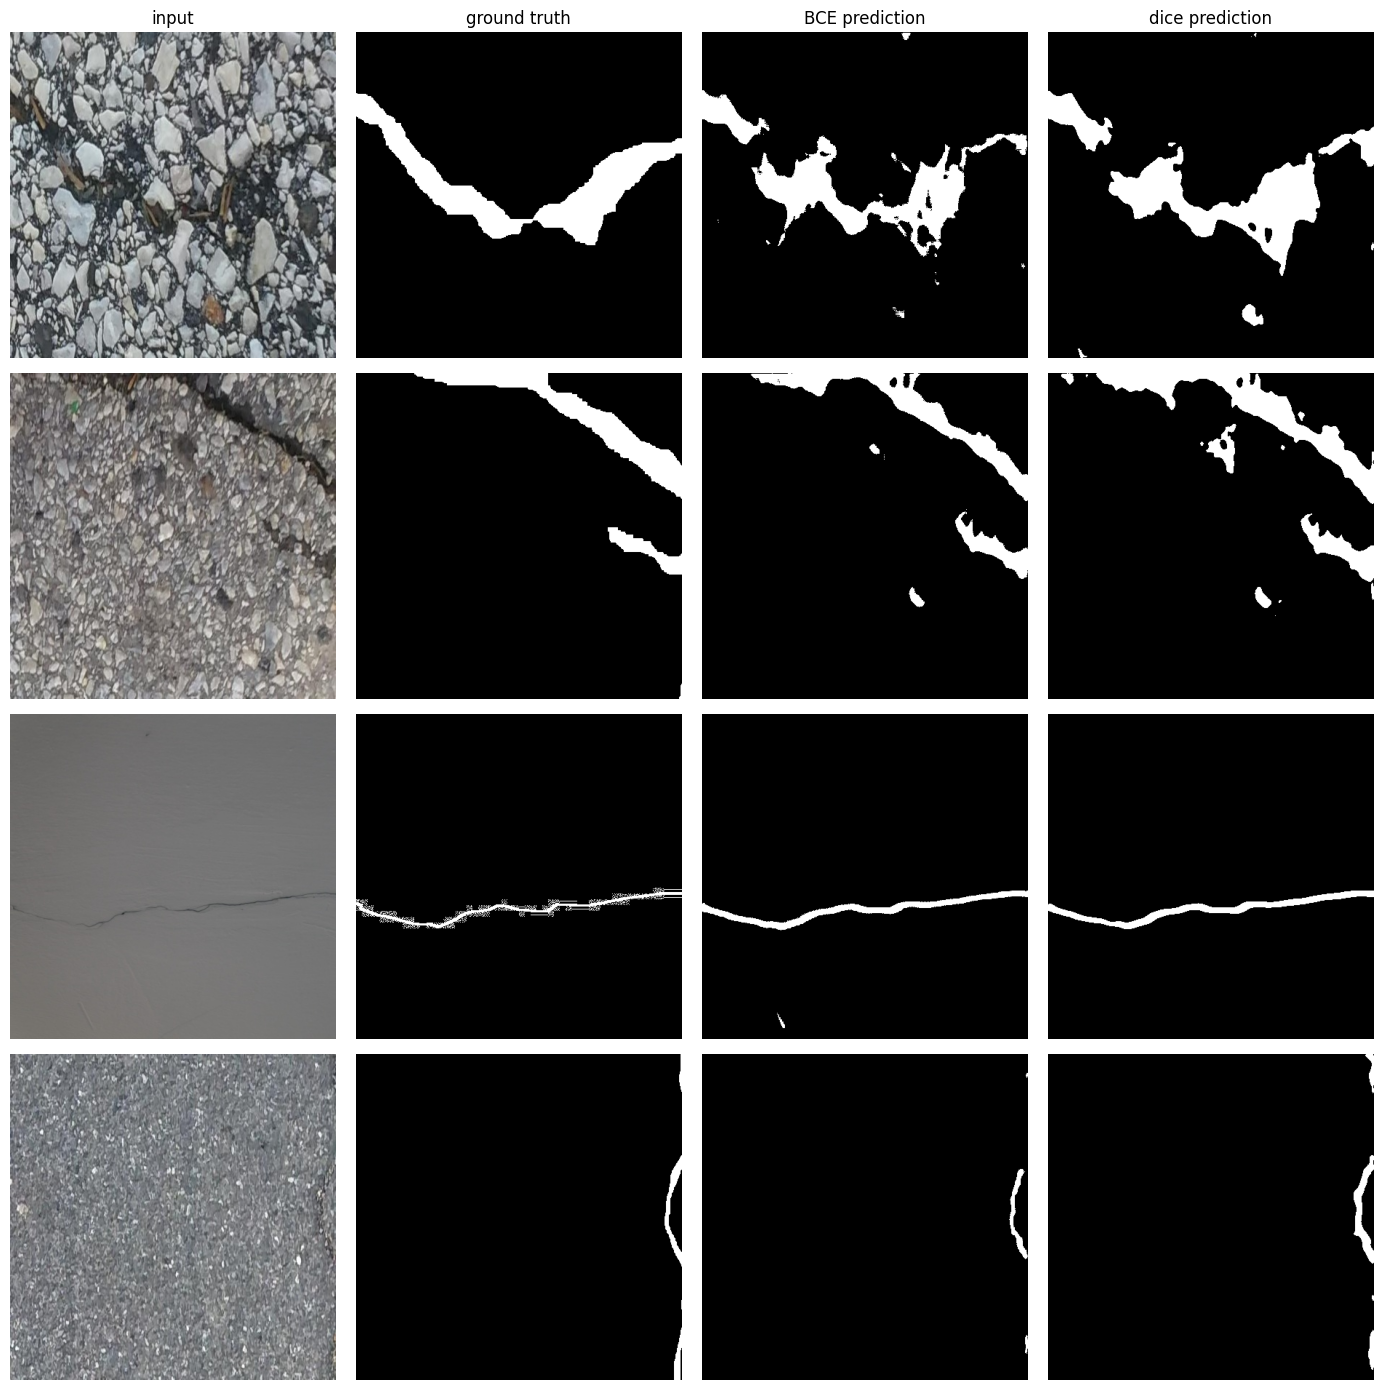

Saved to /content/drive/MyDrive/cse463/figures/fig_bce_failure.png


In [23]:
reg = load_registry()
bce_run = next((v for k, v in reg.items() if k.startswith("B1")), None)

if bce_run and best_run:
    picks = A_test[~A_test["noncrack"]].sample(n=4, random_state=SEED)
    m_bce = keras.models.load_model(bce_run["checkpoint"], compile=False)
    m_best = keras.models.load_model(best_run["checkpoint"], compile=False)

    fig, axes = plt.subplots(4, 4, figsize=(14, 14))
    for i, (_, r) in enumerate(picks.iterrows()):
        bgr = cv2.imread(r["image"], cv2.IMREAD_COLOR)
        gt = (cv2.imread(r["mask"], cv2.IMREAD_GRAYSCALE) > MASK_THRESHOLD).astype(np.float32)
        x_b = make_input(bgr, bce_run["prep"])[None, ...]
        x_g = make_input(bgr, best_run["prep"])[None, ...]
        p_bce = (m_bce.predict(x_b, verbose=0)[0, :, :, 0] > 0.5).astype(np.float32)
        p_best = (m_best.predict(x_g, verbose=0)[0, :, :, 0] > 0.5).astype(np.float32)

        for j, (img, title, cmap) in enumerate([
            (cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), "input", None),
            (gt, "ground truth", "gray"),
            (p_bce, "BCE prediction", "gray"),
            (p_best, BEST_LOSS + " prediction", "gray"),
        ]):
            axes[i][j].imshow(img, cmap=cmap)
            axes[i][j].axis("off")
            if i == 0:
                axes[i][j].set_title(title, fontsize=12)

    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_bce_failure.png", dpi=150)
    plt.show()

    del m_bce, m_best
    keras.backend.clear_session()
    gc.collect()
    print("Saved to", FIG_DIR / "fig_bce_failure.png")

## 21. Figure. Best and worst predictions

Ranks 300 test images by Dice. Shows the four best and four worst cases.

Best cases confirm what the model learned. Worst cases show where it fails.
Common failure modes: low contrast hairline cracks, staining that mimics crack texture.

Saved to Drive as `figures/fig_best_worst.png`.

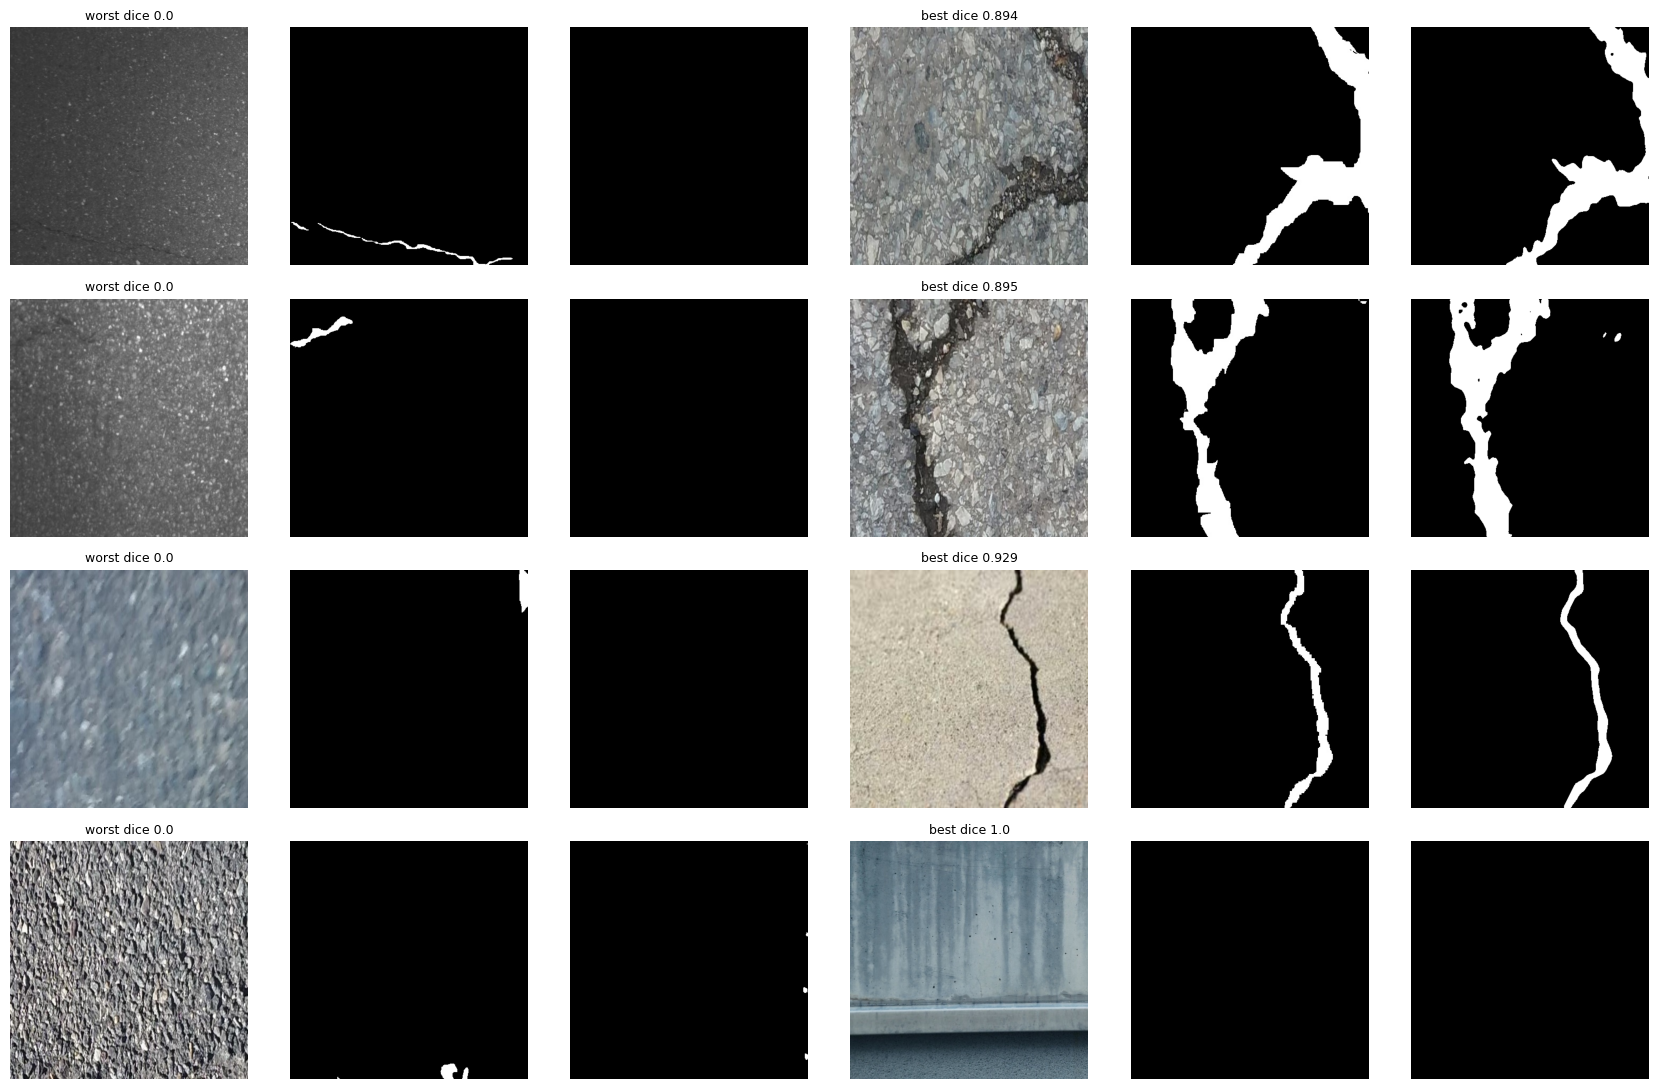

Saved to /content/drive/MyDrive/cse463/figures/fig_best_worst.png


In [24]:
if best_run:
    model = keras.models.load_model(best_run["checkpoint"], compile=False)
    pool = A_test[~A_test["noncrack"]]
    if QUICK_TEST:
        pool = subset(pool, 40)
    else:
        pool = subset(pool, 300)

    scored = []
    for _, r in pool.iterrows():
        bgr = cv2.imread(r["image"], cv2.IMREAD_COLOR)
        gt = (cv2.imread(r["mask"], cv2.IMREAD_GRAYSCALE) > MASK_THRESHOLD).astype(np.float32)
        pr = (model.predict(make_input(bgr, best_run["prep"])[None, ...],
                            verbose=0)[0, :, :, 0] > 0.5).astype(np.float32)
        inter = float((gt * pr).sum())
        d = (2 * inter + SMOOTH) / (gt.sum() + pr.sum() + SMOOTH)
        scored.append((d, r["name"], r["image"], r["mask"], pr))

    scored.sort(key=lambda t: t[0])
    worst, best4 = scored[:4], scored[-4:]

    fig, axes = plt.subplots(4, 6, figsize=(17, 11))
    for col, group in enumerate([worst, best4]):
        for k, (d, name, ip, mp, pr) in enumerate(group):
            bgr = cv2.imread(ip, cv2.IMREAD_COLOR)
            gt = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
            base = col * 3
            axes[k][base + 0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
            axes[k][base + 1].imshow(gt, cmap="gray")
            axes[k][base + 2].imshow(pr, cmap="gray")
            axes[k][base + 0].set_title(("worst " if col == 0 else "best ")
                                        + "dice " + str(round(d, 3)), fontsize=9)
            for j in range(3):
                axes[k][base + j].axis("off")

    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_best_worst.png", dpi=150)
    plt.show()

    del model
    keras.backend.clear_session()
    gc.collect()
    print("Saved to", FIG_DIR / "fig_best_worst.png")

## 22. Figure. Training curves

Plots validation Dice against epoch for Stage A and BCE runs.

Shows convergence speed differences across architectures and the loss comparison.
ResNet50 flat line is visible evidence of the collapse.

Saved to Drive as `figures/fig_training_curves.png`.

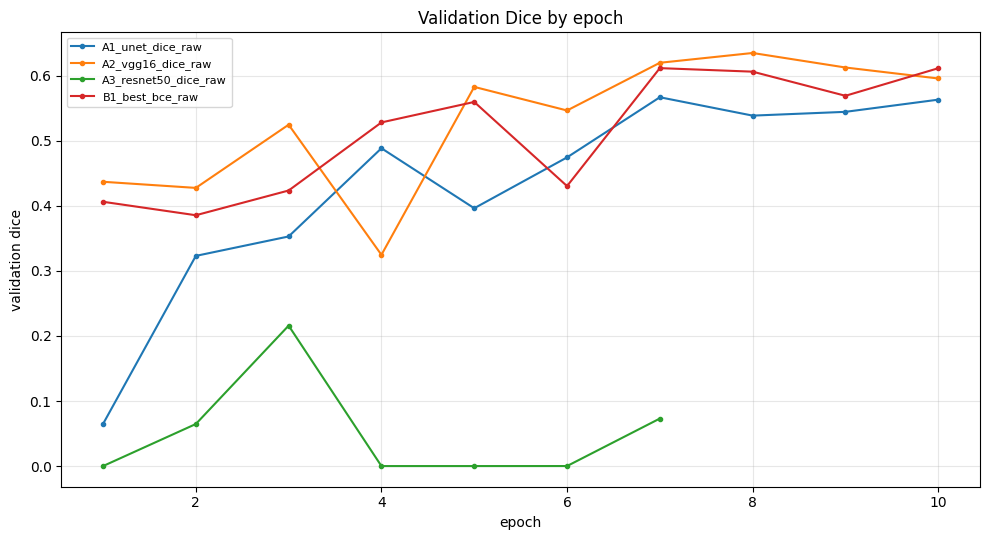

Saved to /content/drive/MyDrive/cse463/figures/fig_training_curves.png


In [25]:
fig, ax = plt.subplots(figsize=(10, 5.5))
plotted = 0
for k, v in sorted(load_registry().items()):
    hp = Path(v["history"])
    if not hp.exists():
        continue
    if not (k.startswith("A") or k.startswith("B1")):
        continue
    h = pd.read_csv(hp)
    if "val_dice" not in h.columns:
        continue
    ax.plot(h["epoch"] + 1, h["val_dice"], marker="o", markersize=3, label=k)
    plotted += 1

if plotted:
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation dice")
    ax.set_title("Validation Dice by epoch")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_training_curves.png", dpi=150)
    plt.show()
    print("Saved to", FIG_DIR / "fig_training_curves.png")
else:
    print("No history files found yet.")

## 23. Final summary

**Best configuration:** VGG16-UNet, Dice loss, raw RGB.

| Metric | Best run (E2, seed 202) |
|---|---|
| Test Dice | 0.6734 |
| IoU | 0.5076 |
| Precision | 0.6690 |
| Recall | 0.6779 |

**Key findings:**

1. VGG16-UNet outperforms U-Net from scratch by 0.073 Dice. ResNet50 collapses under the fixed step budget.
2. BCE does not fail completely at 26 to 1 imbalance. It trades recall for precision differently from Dice and Tversky.
3. Raw RGB outperforms CLAHE and edge preprocessing. The encoder learns edge detection from data.
4. Generalization gap is 0.49 Dice for unseen wall and 0.45 for unseen pavement, confirmed as domain shift by the size-matched control.
5. The official test set inflates Dice by 0.007 due to 48 leaked images.

All outputs are saved to `MyDrive/cse463`.

In [26]:
reg = load_registry()
summary = {
    "quick_test": QUICK_TEST,
    "batch_size": BATCH,
    "crop_size": CROP_SIZE,
    "eval_size": FULL_SIZE,
    "best_architecture": BEST_ARCH,
    "best_loss": BEST_LOSS,
    "best_preprocessing": BEST_PREP,
    "runs_finished": len(reg),
    "splits": {k: {"train": len(v["train"]), "val": len(v["val"]),
                   "test": len(v["test"])} for k, v in SPLITS.items()},
    "dedup_dropped": len(DROP_SET),
    "leaked_test_removed": len(A_test_official) - len(A_test),
}

rule("FINAL SUMMARY")
row("Quick test mode", QUICK_TEST)
row("Runs finished", len(reg))
row("Best architecture", BEST_ARCH)
row("Best loss", BEST_LOSS)
row("Best preprocessing", BEST_PREP)
row("Batch size used", BATCH)
print()
if len(res):
    print("Top five runs by test dice:")
    print(res.sort_values("dice", ascending=False).head(5).to_string(index=False))

(DRIVE_DIR / "final_summary.json").write_text(json.dumps(summary, indent=2))
print()
print("Saved to", DRIVE_DIR / "final_summary.json")
print()
if QUICK_TEST:
    print("This was a quick test. Set QUICK_TEST to False in section 1 and rerun.")
    print("Delete run_registry.json first, so the real runs are not skipped.")
else:
    print("Project run complete.")

FINAL SUMMARY
Quick test mode                               False
Runs finished                                 12
Best architecture                             vgg16_unet
Best loss                                     dice
Best preprocessing                            raw
Batch size used                               48

Top five runs by test dice:
                    run       arch    loss prep     split  train_size   dice    iou  precision  recall  dice_per_image_mean  n_images
       E2_seed_repeat_2 vgg16_unet    dice  raw         A        7922 0.6734 0.5076     0.6690  0.6779               0.5801      1647
      A2_vgg16_dice_raw vgg16_unet    dice  raw         A        7922 0.6707 0.5045     0.6437  0.6999               0.5781      1647
    B2_best_tversky_raw vgg16_unet tversky  raw         A        7922 0.6651 0.4983     0.5905  0.7613               0.5640      1647
       E1_seed_repeat_1 vgg16_unet    dice  raw         A        7922 0.6650 0.4981     0.6484  0.6825           